#Conduct EDA to Learn more about litter in the City of Norfolk


##Two primary Datasets used:

## 1.Litterati
https://data.norfolk.gov/dataset/Litter-Study-Litterati-Litter-Per-Meter/fq5y-c2yn/about_data

### Description:
provides litter per meter measures for areas across norfolk.

### Plan for analysis and why
Use this dataset and the next to find the where and how much of litter which will inform where particular attention will be spent in collecting data with model later

## 2. Norfolk Litter Index
https://data.norfolk.gov/Environment/Litter-Index/nbz2-dgus/about_data

###Description:
Provides litter amounts on ordinal measures of litter along different routes in Norfolk

### Plan for analysis and why
Use this dataset in concert with the prior to get accurate measures of where and how much litter there is In Norfolk, and hopefully create a baseline for litter levels to compare to for future analysis after implementation of model.



In [ ]:
import pandas as pd

urlLitterati = "https://data.norfolk.gov/resource/fq5y-c2yn.json"
urlIndex = "https://data.norfolk.gov/resource/nbz2-dgus.json"

dfLitterati = pd.read_json(urlLitterati)
dfIndex = pd.read_json(urlIndex)

print(dfLitterati.head())


   location_id            location_name  longitude   latitude  \
0        12938           Henneman Drive -76.221902  36.875986   
1        12939            Monmouth Lane -76.181192  36.851911   
2        12940  East Princess Anne Road -76.212753  36.874911   
3        12941  East Princess Anne Road -76.232639  36.866883   
4        12942           Bristol Avenue -76.193833  36.843277   

   distance_spring_2022  distance_summer_2022  distance_fall_2022  \
0                 269.0                 212.0               248.0   
1                 274.0                 286.0               321.0   
2                 261.0                 302.0               246.0   
3                 243.0                 303.0                 NaN   
4                 142.0                 209.0               246.0   

   number_of_objects_of_litter  number_of_objects_of_litter_1  \
0                          8.0                           10.0   
1                         32.0                           21.0   

In [ ]:
print(dfLitterati.describe())

        location_id   longitude    latitude  distance_spring_2022  \
count    300.000000  300.000000  300.000000            259.000000   
mean   13087.500000  -76.251111   36.887500            219.575290   
std       86.746758    0.033429    0.032796            102.392778   
min    12938.000000  -76.317014   36.825783             50.000000   
25%    13012.750000  -76.277539   36.860499            153.500000   
50%    13087.500000  -76.252228   36.882468            213.100000   
75%    13162.250000  -76.224744   36.914940            264.350000   
max    13237.000000  -76.180955   36.967244            583.000000   

       distance_summer_2022  distance_fall_2022  number_of_objects_of_litter  \
count            276.000000          267.000000                   259.000000   
mean             244.910870          236.029963                    19.590734   
std              104.247171           84.130209                    25.214477   
min               71.000000           67.000000           

In [ ]:
#fill NA with column averages for the litter per meter columns for every year
dfLitterati['litter_per_meter_spring_2022'] = dfLitterati['litter_per_meter_spring_2022'].fillna(dfLitterati['litter_per_meter_spring_2022'].mean())
dfLitterati['litter_per_meter_summer_2022'] = dfLitterati['litter_per_meter_summer_2022'].fillna(dfLitterati['litter_per_meter_summer_2022'].mean())
dfLitterati['litter_per_meter_fall_2022'] = dfLitterati['litter_per_meter_fall_2022'].fillna(dfLitterati['litter_per_meter_fall_2022'].mean())


In [ ]:
#get a geographic distribution of litter across Norfolk across the years
#Spring 2022
import pandas as pd
import plotly.express as px

fig = px.scatter_mapbox(
    dfLitterati,
    lat="latitude",
    lon="longitude",
    size="litter_per_meter_spring_2022",
    color="number_of_objects_of_litter",  # color by this column
    color_continuous_scale=[  # green to red
        (0.0, "green"),
        (0.5, "yellow"),
        (1.0, "red")
    ],
    zoom=10,
    mapbox_style="carto-positron"
)

fig.show()

In [ ]:
#get a geographic distribution of litter across Norfolk across the years
#Summer 2022
import pandas as pd
import plotly.express as px

fig = px.scatter_mapbox(
    dfLitterati,
    lat="latitude",
    lon="longitude",
    size="litter_per_meter_summer_2022",
    color="number_of_objects_of_litter_1",  # color by this column
    color_continuous_scale=[  # green to red
        (0.0, "green"),
        (0.5, "yellow"),
        (1.0, "red")
    ],
    zoom=10,
    mapbox_style="carto-positron"
)

fig.show()

In [ ]:
#get a geographic distribution of litter across Norfolk across the years
#Fall 2022
import pandas as pd
import plotly.express as px

fig = px.scatter_mapbox(
    dfLitterati,
    lat="latitude",
    lon="longitude",
    size="litter_per_meter_fall_2022",
    color="number_of_objects_of_litter_2",  # color by this column
    color_continuous_scale=[  # green to red
        (0.0, "green"),
        (0.5, "yellow"),
        (1.0, "red")
    ],
    zoom=10,
    mapbox_style="carto-positron"
)

fig.show()

In [ ]:
import pandas as pd
import plotly.express as px

# Sample reshaped dataframe
# Replace with your actual data reshaped to long format
df_long = pd.melt(
    dfLitterati,
    id_vars=['latitude', 'longitude'],
    value_vars=[
        'litter_per_meter_spring_2022',
        'litter_per_meter_summer_2022',
        'litter_per_meter_fall_2022'
    ],
    var_name='season',
    value_name='litter_per_meter'
)

# Clean season labels
df_long['season'] = (
    df_long['season']
    .str.replace('litter_per_meter_', '', regex=False)
    .str.replace('_2022', '', regex=False)
    .str.title()
)

# Create animated map
fig = px.scatter_mapbox(
    df_long,
    lat="latitude",
    lon="longitude",
    color="litter_per_meter",
    size="litter_per_meter",
    animation_frame="season",
    color_continuous_scale=[  # green to red
        (0.0, "green"),
        (0.5, "yellow"),
        (1.0, "red")
    ],
    zoom=10,
    mapbox_style="carto-positron"
)

# Customize animation settings
fig.update_layout(
    mapbox_accesstoken='your_mapbox_token_if_needed',
    margin={"r":0,"t":0,"l":0,"b":0},
    updatemenus=[{
        "buttons": [{
            "args": [None, {"frame": {"duration": 1500, "redraw": True},
                            "fromcurrent": True, "transition": {"duration": 500}}],
            "label": "Play",
            "method": "animate"
        }, {
            "args": [[None], {"frame": {"duration": 0, "redraw": False},
                              "mode": "immediate", "transition": {"duration": 0}}],
            "label": "Pause",
            "method": "animate"
        }],
        "direction": "left",
        "pad": {"r": 10, "t": 70},
        "showactive": False,
        "type": "buttons",
        "x": 0.1,
        "xanchor": "right",
        "y": 0,
        "yanchor": "top"
    }],
    sliders=[{
        "currentvalue": {"prefix": "Season: "},
        "pad": {"t": 30},
        "steps": []
    }]
)

# Optional: Make it loop continuously
fig["layout"]["sliders"][0]["steps"] = [
    {
        "args": [[season], {"frame": {"duration": 1500, "redraw": True},
                            "mode": "immediate", "transition": {"duration": 500}}],
        "label": season,
        "method": "animate"
    }
    for season in sorted(df_long['season'].unique())
]

fig.show()



##Now lets do the same thing for the Litter Index compiled internally by KNB

In [ ]:
print(dfIndex.head())

  ward_route  _2010  _2011  _2012  _2013  _2014  _2015  _2016  _2017  _2018  \
0  Ward 1-1a    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   
1  Ward 1-1b    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0    1.0   
2  Ward 1-1c    1.0    1.0    1.0    1.0    1.0    1.0    1.0    2.0    1.0   
3  Ward 1-1d    1.0    2.0    1.0    1.0    1.0    1.0    1.0    NaN    1.0   
4  Ward 1-1e    1.0    1.0    1.0    1.0    1.0    NaN    1.0    NaN    NaN   

   _2019  
0    1.0  
1    1.0  
2    1.0  
3    1.0  
4    NaN  


In [ ]:
print(dfIndex.describe())

            _2010       _2011       _2012       _2013       _2014       _2015  \
count  366.000000  426.000000  426.000000  366.000000  366.000000  306.000000   
mean     1.613333    1.741620    1.577840    1.716667    1.476639    1.641634   
std      0.601040    0.622325    0.672751    0.667604    0.561285    0.654735   
min      1.000000    1.000000    1.000000    1.000000    1.000000    1.000000   
25%      1.000000    1.000000    1.000000    1.000000    1.000000    1.000000   
50%      1.605000    2.000000    1.185000    1.815000    1.000000    1.750000   
75%      2.000000    2.000000    2.000000    2.000000    2.000000    2.000000   
max      4.000000    3.000000    4.000000    3.500000    3.000000    4.000000   

            _2016       _2017       _2018       _2019  
count  366.000000  246.000000  305.000000  294.000000  
mean     1.494973    1.510976    1.789934    1.594235  
std      0.631552    0.610891    0.705671    0.609949  
min      1.000000    1.000000    1.000000    1

In [ ]:
# this dataset does not have lat long measures so were going to hard code them in so that we can
#visualize geographic distributions easier and more accurately
import pandas as pd
import re

# Load from API
url = "https://data.norfolk.gov/resource/nbz2-dgus.json"
df = pd.read_json(url)

# Normalize column
df.rename(columns={"Ward-Route": "ward_route"}, inplace=True)

# Normalize 'Ward 1-1a' → 'Ward 1 Route 1'
def normalize_ward_route(raw):
    match = re.match(r"Ward (\d+)-(\d+)", str(raw))
    if match:
        ward, route = match.groups()
        return f"Ward {ward} Route {route}"
    return None

df['normalized_route'] = df['ward_route'].apply(normalize_ward_route)

# Coordinates mapping
coords = {
    "Ward 1 Route 1": (36.8893, -76.3125), "Ward 1 Route 2": (36.8927, -76.3088),
    "Ward 1 Route 3": (36.9038, -76.3035), "Ward 1 Route 4": (36.9485, -76.2702),
    "Ward 1 Route 5": (36.9527, -76.2718), "Ward 1 Route 6": (36.9550, -76.2720),
    "Ward 1 Route 7": (36.9604, -76.2735), "Ward 1 Route 8": (36.9623, -76.2752),
    "Ward 1 Route 9": (36.9240, -76.2490), "Ward 1 Route 10": (36.9305, -76.2664),
    "Ward 1 Route 11": (36.9089, -76.2710), "Ward 1 Route 12": (36.9115, -76.2754),
    "Ward 2 Route 1": (36.9175, -76.2495), "Ward 2 Route 2": (36.9170, -76.2460),
    "Ward 2 Route 3": (36.9161, -76.2766), "Ward 2 Route 4": (36.9150, -76.2535),
    "Ward 2 Route 5": (36.8730, -76.2915), "Ward 2 Route 6": (36.8858, -76.2996),
    "Ward 2 Route 7": (36.8784, -76.2997), "Ward 2 Route 8": (36.8685, -76.2945),
    "Ward 2 Route 9": (36.8620, -76.2880), "Ward 2 Route 10": (36.8505, -76.2880),
    "Ward 2 Route 11": (36.8550, -76.2870), "Ward 2 Route 12": (36.8665, -76.2872),
    "Ward 3 Route 1": (36.9200, -76.2380), "Ward 3 Route 2": (36.9175, -76.2360),
    "Ward 3 Route 3": (36.9070, -76.2325), "Ward 3 Route 4": (36.8845, -76.2310),
    "Ward 3 Route 5": (36.8753, -76.2353), "Ward 3 Route 6": (36.8677, -76.2355),
    "Ward 3 Route 7": (36.8530, -76.2402), "Ward 3 Route 8": (36.8505, -76.2380),
    "Ward 3 Route 9": (36.8610, -76.2390), "Ward 3 Route 10": (36.8635, -76.2425),
    "Ward 3 Route 11": (36.8655, -76.2460), "Ward 3 Route 12": (36.8623, -76.2480),
    "Ward 4 Route 1": (36.8570, -76.2735), "Ward 4 Route 2": (36.8500, -76.2752),
    "Ward 4 Route 3": (36.8407, -76.2737), "Ward 4 Route 4": (36.8374, -76.2565),
    "Ward 4 Route 5": (36.8495, -76.2670), "Ward 4 Route 6": (36.8655, -76.2220),
    "Ward 4 Route 7": (36.8670, -76.2165), "Ward 4 Route 8": (36.8662, -76.2130),
    "Ward 4 Route 9": (36.8674, -76.2100), "Ward 4 Route 10": (36.8665, -76.2055),
    "Ward 4 Route 11": (36.8695, -76.2030), "Ward 4 Route 12": (36.8720, -76.2010),
    "Ward 5 Route 1": (36.8755, -76.2000), "Ward 5 Route 2": (36.8780, -76.1980),
    "Ward 5 Route 3": (36.9130, -76.1780), "Ward 5 Route 4": (36.9155, -76.1772),
    "Ward 5 Route 5": (36.9160, -76.1830), "Ward 5 Route 6": (36.9168, -76.1890),
    "Ward 5 Route 7": (36.9095, -76.1990), "Ward 5 Route 8": (36.9090, -76.2020),
    "Ward 5 Route 9": (36.9100, -76.2045), "Ward 5 Route 10": (36.9130, -76.2080),
    "Ward 5 Route 11": (36.9145, -76.2110), "Ward 5 Route 12": (36.9155, -76.2150),
}

# Map coordinates
df['approx_lat'] = df['normalized_route'].map(lambda x: coords.get(x, (None, None))[0])
df['approx_lon'] = df['normalized_route'].map(lambda x: coords.get(x, (None, None))[1])

# Display result
print(df.head(30))


      ward_route  _2010  _2011  _2012  _2013  _2014  _2015  _2016  _2017  \
0      Ward 1-1a    1.0   1.00   1.00    1.0    1.0   1.00    1.0   1.00   
1      Ward 1-1b    1.0   1.00   1.00    1.0    1.0   1.00    1.0   1.00   
2      Ward 1-1c    1.0   1.00   1.00    1.0    1.0   1.00    1.0   2.00   
3      Ward 1-1d    1.0   2.00   1.00    1.0    1.0   1.00    1.0    NaN   
4      Ward 1-1e    1.0   1.00   1.00    1.0    1.0    NaN    1.0    NaN   
5      Ward 1-1f    NaN   2.00   1.00    NaN    NaN    NaN    NaN    NaN   
6   Ward 1-1 Avg    1.0   1.33   1.00    1.0    1.0   1.00    1.0   1.33   
7      Ward 1-2a    2.0   1.00   2.00    1.0    2.0   2.00    1.0   2.00   
8      Ward 1-2b    2.0   1.00   2.00    2.0    2.0   2.00    1.0   2.00   
9      Ward 1-2c    2.0   2.00   2.00    1.5    1.0   2.00    1.0   3.00   
10     Ward 1-2d    2.0   2.00   1.00    1.0    2.0   2.00    1.0    NaN   
11     Ward 1-2e    3.0   2.00   2.00    2.0    2.0    NaN    1.0    NaN   
12     Ward 

In [ ]:
# Step 1: Get all columns that look like "_2010" to "_2019"
year_cols = [col for col in df.columns if col.startswith('_20') and col[1:].isdigit() and 2010 <= int(col[1:]) <= 2019]

# Step 2: Melt to long format
df_long = df.melt(
    id_vars=['ward_route', 'approx_lat', 'approx_lon'],
    value_vars=year_cols,
    var_name='year',
    value_name='litter_index'
)

# Step 3: Strip the underscore from 'year'
df_long['year'] = df_long['year'].str[1:]

print(df_long.head())


  ward_route  approx_lat  approx_lon  year  litter_index
0  Ward 1-1a     36.8893    -76.3125  2010           1.0
1  Ward 1-1b     36.8893    -76.3125  2010           1.0
2  Ward 1-1c     36.8893    -76.3125  2010           1.0
3  Ward 1-1d     36.8893    -76.3125  2010           1.0
4  Ward 1-1e     36.8893    -76.3125  2010           1.0


In [ ]:
df_long["litter_index"] = df_long["litter_index"].fillna(df_long["litter_index"].mean())



In [ ]:
import plotly.express as px

fig = px.scatter_mapbox(
    df_long,
    lat="approx_lat",
    lon="approx_lon",
    color="litter_index",
    size="litter_index",
    animation_frame="year",
    color_continuous_scale="YlOrRd",
    zoom=10,
    mapbox_style="carto-positron"
)

fig.show()



In [ ]:
# Only keep rows where 'ward_route' contains 'Avg'
df_avg = df[df['ward_route'].str.contains("Avg", case=False, na=False)]


In [ ]:
# Melt the year columns as before
year_cols = [col for col in df_avg.columns if col.startswith('_20') and col[1:].isdigit() and 2010 <= int(col[1:]) <= 2019]

df_avg_long = df_avg.melt(
    id_vars=['ward_route', 'approx_lat', 'approx_lon'],
    value_vars=year_cols,
    var_name='year',
    value_name='litter_index'
)

# Strip leading underscore from year
df_avg_long['year'] = df_avg_long['year'].str[1:]

# Plot
fig = px.scatter_mapbox(
    df_avg_long.dropna(subset=["litter_index"]),
    lat="approx_lat",
    lon="approx_lon",
    color="litter_index",
    size="litter_index",
    animation_frame="year",
    color_continuous_scale="YlOrRd",
    zoom=10,
    mapbox_style="carto-positron"
)

fig.show()


# Creating a new model based on a dataset of 10,771 images. Yolo V11

###Instructions:
1. download datasets from roboflow in yolov8 format. this will include all images and accompanying annotations

#first we have to start by merging all 6 datasets into one

In [ ]:
import os
os.environ["LC_ALL"] = "C.UTF-8"
os.environ["LANG"] = "C.UTF-8"


## Now we have to check we don't have duplicate image or label files with the same name

In [ ]:
#Train set
import os

# Define paths to merged images and labels folders
merged_images_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/images"
merged_labels_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels"

# Ensure directories exist
os.makedirs(merged_images_dir, exist_ok=True)
os.makedirs(merged_labels_dir, exist_ok=True)

# Track existing filenames to avoid duplicates
existing_filenames = set()
counter = 0  # Unique counter for renaming

# Process images
for img_name in os.listdir(merged_images_dir):
    base, ext = os.path.splitext(img_name)

    # If the filename already exists, rename it
    if img_name in existing_filenames:
        new_name = f"img_{counter}{ext}"
        os.rename(os.path.join(merged_images_dir, img_name), os.path.join(merged_images_dir, new_name))

        # Rename corresponding label
        old_label = os.path.join(merged_labels_dir, f"{base}.txt")
        new_label = os.path.join(merged_labels_dir, f"img_{counter}.txt")
        if os.path.exists(old_label):
            os.rename(old_label, new_label)

        counter += 1  # Increment counter for unique naming
    else:
        existing_filenames.add(img_name)  # Mark filename as seen

print("Duplicate renaming completed successfully!")

Duplicate renaming completed successfully!


In [ ]:
#ensuring the above step worked as expected:
import os

# Define paths
merged_images_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/images"
merged_labels_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels"

# Count files
num_images = len(os.listdir(merged_images_dir))
num_labels = len(os.listdir(merged_labels_dir))

print(f"Total images: {num_images}")
print(f"Total labels: {num_labels}")

# Ensure labels match images
image_files = {os.path.splitext(f)[0] for f in os.listdir(merged_images_dir)}
label_files = {os.path.splitext(f)[0] for f in os.listdir(merged_labels_dir)}

missing_labels = image_files - label_files
missing_images = label_files - image_files

print(f"Images missing labels: {missing_labels}")
print(f"Labels missing images: {missing_images}")


Total images: 10311
Total labels: 11232
Images missing labels: set()
Labels missing images: {'VID_20230723_103041_0038_MP4-57_jpg.rf.cfc1cd59a5947839f83d1fa5fb371d72', 'VID_20230723_104017_0043_MP4-22_jpg.rf.b0cb0b925c3d63b6fbdcfe4c54420668', 'VID_20230630_175708_0023_MP4-28_jpg.rf.45e4109e6daae29bcbc1cd1a462fb30c', 'VID_20230623_103349_0021_MP4-4_jpg.rf.130cf08cec7e53d6554e65a4536fd8a7', 'VID_20230630_175827_0024_MP4-15_jpg.rf.401ef561e5926cf67e7e70d597b23e21', 'VID_20230723_103041_0038_MP4-15_jpg.rf.72ee52111d8778b1bf6eb668f1b61900', 'VID_20230630_175959_0025_MP4-27_jpg.rf.138ce31d6ba5b37d5ee97d67f54c635d', 'VID_20230723_101947_0036_MP4-59_jpg.rf.ed962057a5a005270dfa57535ff82bd0', 'VID_20230723_104017_0043_MP4-13_jpg.rf.3ec1203f167764e5ae8013ee018fecc8', 'VID_20230630_180618_0028_MP4-34_jpg.rf.50672ada40ab9dd860267bdabd5158c1', 'VID_20230623_103349_0021_MP4-61_jpg.rf.0e79d848bf23f4d3c6617d4e19e8ae3d', 'VID_20230723_104017_0043_MP4-52_jpg.rf.136e35a4780ae75da01179d5fa2c687c', 'VID_202

In [ ]:
#Valid set
import os

# Define paths to merged images and labels folders
merged_images_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/valid/images"
merged_labels_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/valid/labels"

# Ensure directories exist
os.makedirs(merged_images_dir, exist_ok=True)
os.makedirs(merged_labels_dir, exist_ok=True)

# Track existing filenames to avoid duplicates
existing_filenames = set()
counter = 0  # Unique counter for renaming

# Process images
for img_name in os.listdir(merged_images_dir):
    base, ext = os.path.splitext(img_name)

    # If the filename already exists, rename it
    if img_name in existing_filenames:
        new_name = f"img_{counter}{ext}"
        os.rename(os.path.join(merged_images_dir, img_name), os.path.join(merged_images_dir, new_name))

        # Rename corresponding label
        old_label = os.path.join(merged_labels_dir, f"{base}.txt")
        new_label = os.path.join(merged_labels_dir, f"img_{counter}.txt")
        if os.path.exists(old_label):
            os.rename(old_label, new_label)

        counter += 1  # Increment counter for unique naming
    else:
        existing_filenames.add(img_name)  # Mark filename as seen

print("Duplicate renaming completed successfully!")

Duplicate renaming completed successfully!


In [ ]:
#ensuring the above step worked as expected:
import os

# Define paths
merged_images_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/valid/images"
merged_labels_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/valid/labels"

# Count files
num_images = len(os.listdir(merged_images_dir))
num_labels = len(os.listdir(merged_labels_dir))

print(f"Total images: {num_images}")
print(f"Total labels: {num_labels}")

# Ensure labels match images
image_files = {os.path.splitext(f)[0] for f in os.listdir(merged_images_dir)}
label_files = {os.path.splitext(f)[0] for f in os.listdir(merged_labels_dir)}

missing_labels = image_files - label_files
missing_images = label_files - image_files

print(f"Images missing labels: {missing_labels}")
print(f"Labels missing images: {missing_images}")

Total images: 1405
Total labels: 1405
Images missing labels: set()
Labels missing images: set()


In [ ]:
#test set
import os

# Define paths to merged images and labels folders
merged_images_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/test/images"
merged_labels_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/test/labels"

# Ensure directories exist
os.makedirs(merged_images_dir, exist_ok=True)
os.makedirs(merged_labels_dir, exist_ok=True)

# Track existing filenames to avoid duplicates
existing_filenames = set()
counter = 0  # Unique counter for renaming

# Process images
for img_name in os.listdir(merged_images_dir):
    base, ext = os.path.splitext(img_name)

    # If the filename already exists, rename it
    if img_name in existing_filenames:
        new_name = f"img_{counter}{ext}"
        os.rename(os.path.join(merged_images_dir, img_name), os.path.join(merged_images_dir, new_name))

        # Rename corresponding label
        old_label = os.path.join(merged_labels_dir, f"{base}.txt")
        new_label = os.path.join(merged_labels_dir, f"img_{counter}.txt")
        if os.path.exists(old_label):
            os.rename(old_label, new_label)

        counter += 1  # Increment counter for unique naming
    else:
        existing_filenames.add(img_name)  # Mark filename as seen

print("Duplicate renaming completed successfully!")

Duplicate renaming completed successfully!


In [ ]:
#ensuring the above step worked as expected:
import os

# Define paths
merged_images_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/test/images"
merged_labels_dir = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/test/labels"

# Count files
num_images = len(os.listdir(merged_images_dir))
num_labels = len(os.listdir(merged_labels_dir))

print(f"Total images: {num_images}")
print(f"Total labels: {num_labels}")

# Ensure labels match images
image_files = {os.path.splitext(f)[0] for f in os.listdir(merged_images_dir)}
label_files = {os.path.splitext(f)[0] for f in os.listdir(merged_labels_dir)}

missing_labels = image_files - label_files
missing_images = label_files - image_files

print(f"Images missing labels: {missing_labels}")
print(f"Labels missing images: {missing_images}")

Total images: 1396
Total labels: 1396
Images missing labels: set()
Labels missing images: set()


## creating a data.yaml file for the newly merged dataset

In [ ]:
#checking for classes in the dataset to identify them for the yaml file
import os

labels_dir = "//content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels"

# Get all label files
label_files = [os.path.join(labels_dir, f) for f in os.listdir(labels_dir) if f.endswith(".txt")]

# Extract class IDs from the first few label files
class_ids = set()
for label_file in label_files[:50]:  # Check first 50 files
    with open(label_file, "r") as f:
        for line in f:
            class_id = int(line.split()[0])  # Class ID is the first number in each line
            class_ids.add(class_id)

print(f"Number of classes: {len(class_ids)}")
print(f"Class IDs: {class_ids}")


Number of classes: 1
Class IDs: {0}


In [ ]:
#create the YAML file
yaml_content = f"""train: /content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/images
val: /content/drive/MyDrive/L.O.D.M. V3/merged_dataset/valid/images

nc: 1
names: ["Litter"]
"""

# Save the YAML file
yaml_path = "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset/data.yaml"
with open(yaml_path, "w") as f:
    f.write(yaml_content)

print(f"data.yaml created at {yaml_path}")


data.yaml created at /content/drive/MyDrive/L.O.D.M. V3/merged_dataset/data.yaml


In [ ]:
with open(yaml_path, "r") as f:
    print(f.read())

train: /content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/images
val: /content/drive/MyDrive/L.O.D.M. V3/merged_dataset/valid/images

nc: 1
names: ["Litter"]



# "This is where the fun begins". Now we train the model using the small size V8 model

In [ ]:
!pip install ultralytics

In [ ]:
!ls -lh /content/drive/MyDrive/L.O.D.M\ V2/merged_dataset/


total 17K
-rw------- 1 root root  164 Feb 13 04:18 data.yaml
drwx------ 6 root root 4.0K Feb 13 14:08 runs
drwx------ 3 root root 4.0K Feb 12 15:29 test
drwx------ 3 root root 4.0K Feb 12 15:28 train
drwx------ 3 root root 4.0K Feb 12 15:28 valid


In [ ]:
import os

model_path = "/content/drive/MyDrive/L.O.D.M V2/merged_dataset/yolo11m.pt"
if os.path.exists(model_path):
    print("Model file found!")
else:
    print("Model file NOT found.")


Model file NOT found. Downloading now...


In [ ]:
from ultralytics import YOLO

model_path = "/content/drive/MyDrive/L.O.D.M V2/merged_dataset/yolo11m.pt"

try:
    model = YOLO(model_path)  # Explicitly use medium model
except FileNotFoundError:
    print("Error: yolo11m.pt not found! Please download it manually.")
    raise

In [ ]:
!nvidia-smi


Thu Aug 21 14:26:28 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from ultralytics import YOLO

# Load YOLOv11 model
model = YOLO('/content/drive/MyDrive/L.O.D.M V2/merged_dataset/yolo11m.pt')

# Train the model
model.train(
    data='/content/drive/MyDrive/L.O.D.M V2/merged_dataset/data.yaml',
    epochs=100,
    imgsz=640, # bump it up in terms of
    batch=16, # bump up batch size
    save=True,
    name='L.O.D.M. detections',
    project='/content/drive/MyDrive/L.O.D.M V2/merged_dataset/runs'
)

Ultralytics 8.3.75 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=/content/drive/MyDrive/L.O.D.M V2/merged_dataset/yolo11m.pt, data=/content/drive/MyDrive/L.O.D.M V2/merged_dataset/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=/content/drive/MyDrive/L.O.D.M V2/merged_dataset/runs, name=L.O.D.M. detections6, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks

train: Scanning /content/drive/MyDrive/L.O.D.M V2/merged_dataset/train/labels.cache... 7913 images, 211 backgrounds, 0 corrupt: 100%|██████████| 7913/7913 [00:00<?, ?it/s]

train: WARNING ⚠️ /content/drive/MyDrive/L.O.D.M V2/merged_dataset/train/images/img1644_jpg.rf.f9da3ad999f0a3dfe19f9c0e0babdb9a.jpg: 1 duplicate labels removed
train: WARNING ⚠️ /content/drive/MyDrive/L.O.D.M V2/merged_dataset/train/images/img1778_jpg.rf.a488ec2f4c3a86a431477cf8eb919cee.jpg: 1 duplicate labels removed
train: WARNING ⚠️ /content/drive/MyDrive/L.O.D.M V2/merged_dataset/train/images/img2757_jpg.rf.12abaefdd585a668270092b4cb0abad7.jpg: 1 duplicate labels removed
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 10033, len(boxes) = 43455. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


/usr/local/lib/python3.11/dist-packages/albumentations/__init__.py:28: UserWarning: A new version of Albumentations is available: '2.0.4' (you have '2.0.3'). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
val: Scanning /content/drive/MyDrive/L.O.D.M V2/merged_dataset/valid/labels.cache... 1780 images, 53 backgrounds, 0 corrupt: 100%|██████████| 1780/1780 [00:00<?, ?it/s]

WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 2580, len(boxes) = 9246. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.


... (100 outputs left out)

                   all       1780       9246      0.843      0.641      0.733      0.432

50 epochs completed in 4.849 hours.
Optimizer stripped from /content/drive/MyDrive/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6/weights/last.pt, 40.5MB
Optimizer stripped from /content/drive/MyDrive/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6/weights/best.pt, 40.5MB

Validating /content/drive/MyDrive/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6/weights/best.pt...
Ultralytics 8.3.75 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11m summary (fused): 303 layers, 20,030,803 parameters, 0 gradients, 67.6 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 56/56 [00:34<00:00,  1.61it/s]


                   all       1780       9246      0.842      0.641      0.732      0.432
Speed: 0.2ms preprocess, 10.8ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/drive/MyDrive/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7923c820ce50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
from ultralytics import YOLO

# Load the saved model
model_path = '/content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6/weights/best.pt'
model = YOLO(model_path)

print(f"Model loaded from: {model_path}")

Model loaded from: /content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6/weights/best.pt


In [ ]:
# Validate the model
metrics = model.val(data='/content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/data.yaml')

# Print validation results
print(metrics)

Ultralytics 8.3.183 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.6 GFLOPs


val: Fast image access ✅ (ping: 1.3±1.6 ms, read: 0.1±0.1 MB/s, size: 63.7 KB)


val: Scanning /content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/valid/labels... 1780 images, 53 backgrounds, 0 corrupt: 100%|██████████| 1780/1780 [16:30<00:00,  1.80it/s]


val: New cache created: /content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/valid/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 2580, len(boxes) = 9246. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 112/112 [00:55<00:00,  2.03it/s]


                   all       1780       9246      0.844      0.641      0.733      0.434
Speed: 0.5ms preprocess, 25.2ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to runs/detect/val
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f1af1b61d30>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.03303


image 1/1 /content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/test/images/img1929_jpg.rf.d2ec0a3a006c89e3106889b31f2aebb5.jpg: 640x640 6 Litters, 36.8ms
Speed: 2.1ms preprocess, 36.8ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to runs/detect/predict4


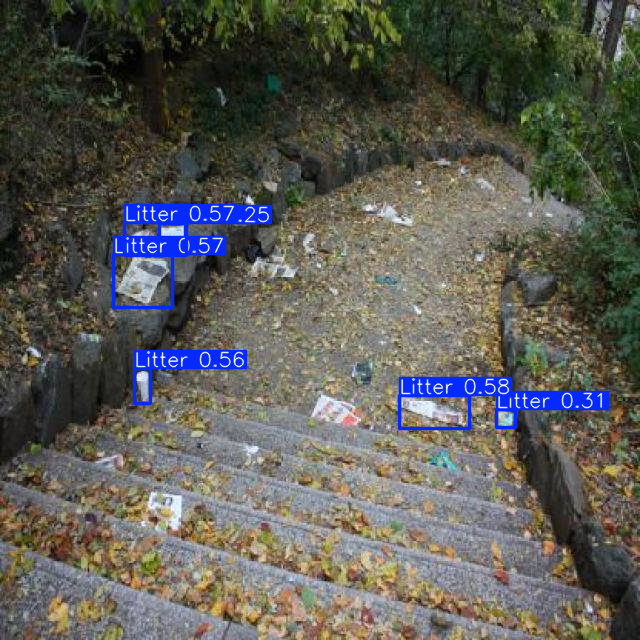

In [ ]:
# Path to a test image
test_image_path = '/content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/test/images/img1929_jpg.rf.d2ec0a3a006c89e3106889b31f2aebb5.jpg'

# Perform inference
results = model.predict(source=test_image_path, save=True, conf=0.25)

# Display the results
results[0].show()

In [ ]:
import os
from PIL import Image

# Path to a test image
test_image_path = '/content/drive/MyDrive/Litter Detection Dataset.v1i.yolov11/Litter Dataset.v1i.yolov11/GOPR0336.JPG'

# Define your custom save directory
custom_save_dir = '/content/drive/MyDrive/Litter Detection Dataset.v1i.yolov11/Litter Dataset.v1i.yolov11/resultsfrombest'

# Create the directory if it doesn't exist
os.makedirs(custom_save_dir, exist_ok=True)

# Perform inference without saving automatically
results = model.predict(source=test_image_path, conf=0.25, save=False)

# Save the result image manually
result_img = results[0].plot()  # This returns a numpy image with predictions plotted
result_pil = Image.fromarray(result_img)

# Save to your custom directory
image_name = os.path.basename(test_image_path)
result_pil.save(os.path.join(custom_save_dir, f"pred_{image_name}"))

# Optionally display it
result_pil.show()



image 1/1 /content/drive/MyDrive/Litter Detection Dataset.v1i.yolov11/Litter Dataset.v1i.yolov11/GOPR0336.JPG: 480x640 2 Litters, 29.2ms
Speed: 3.2ms preprocess, 29.2ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)


In [ ]:
# Set locale to UTF-8 before running shell commands
import locale

def set_utf8_locale():
    # Try setting locale with UTF-8
    try:
        locale.setlocale(locale.LC_ALL, 'en_US.UTF-8')
    except locale.Error:
        # If 'en_US.UTF-8' is not available, try 'en_US.utf8'
        try:
            locale.setlocale(locale.LC_ALL, 'en_US.utf8')
        except locale.Error:
            # If both fail, print a warning and proceed
            print("Warning: Could not set UTF-8 locale. Some characters might not display correctly.")

# Call the function to set UTF-8 locale before running your shell commands
set_utf8_locale()

#!sudo apt-get update
#!sudo apt-get install -y locales
#!sudo locale-gen en_US.UTF-8
#!sudo update-locale LANG=en_US.UTF-8
#!pip install gradio
#==3.38.0

In [ ]:
import os
os.environ["LC_ALL"] = "C.UTF-8"
os.environ["LANG"] = "C.UTF-8"

In [ ]:
# !sudo apt-get update
# !sudo apt-get install -y locales
# !sudo locale-gen en_US.UTF-8
# !sudo update-locale LANG=en_US.UTF-8
!pip install gradio

#==3.38.0

In [ ]:
from ultralytics import YOLO
model_path = '/content/drive/MyDrive/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6/weights/best.pt'
model = YOLO(model_path)
test_image_path = '/content/drive/MyDrive/L.O.D.M V2/merged_dataset/test/images/000789_jpg.rf.686be1bc8395558edd1562b43b810113.jpg'
results = model(test_image_path)
num_boxes = len(results[0].boxes)
print(f"Number of boxes detected: {num_boxes}")


image 1/1 /content/drive/MyDrive/L.O.D.M V2/merged_dataset/test/images/000789_jpg.rf.686be1bc8395558edd1562b43b810113.jpg: 640x640 4 Litters, 36.8ms
Speed: 2.7ms preprocess, 36.8ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)
Number of boxes detected: 4


In [ ]:
def classify_litter(num_boxes):
    if num_boxes == 0:
        return "Level 1 - Little to no itter"
    elif 1 <= num_boxes <= 5:
        return "Level 4 - Low Litter"
    elif 6 <= num_boxes <= 15:
        return "Level 3 - Moderate Litter"
    elif 16 <= num_boxes <= 30:
        return "Level 2 - High Litter"
    else:
        return "Level 1 - Severe Litter"

In [ ]:
results = model(test_image_path)
num_boxes = len(results[0].boxes)
litter_level = classify_litter(num_boxes)
print(f"Litter Level: {litter_level} (Detected {num_boxes} pieces of litter)")


image 1/1 /content/drive/MyDrive/L.O.D.M V2/merged_dataset/test/images/000789_jpg.rf.686be1bc8395558edd1562b43b810113.jpg: 640x640 4 Litters, 37.0ms
Speed: 2.4ms preprocess, 37.0ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
Litter Level: Level 4 - Low Litter (Detected 4 pieces of litter)


In [ ]:
import gradio as gr
import torch
import numpy as np
from PIL import Image, UnidentifiedImageError
from ultralytics import YOLO

# Load YOLOv8 model
model_path = '/content/drive/MyDrive/L.O.D.M. v4 entire dataset/L.O.D.M V2/merged_dataset/runs/L.O.D.M. detections6/weights/best.pt'
model = YOLO(model_path)

# Define litter classification
def classify_litter(num_boxes):
    if 0 <= num_boxes <= 2:
        return "Level 1 - Little to no litter"
    elif 3 <= num_boxes <= 15:
        return "Level 2 - Litter in the amount that can be collected by a single person"
    elif 16 <= num_boxes <= 30:
        return "Level 3 - Litter in the amount that would require collection by a team"
    else:
        return "Level 4 - Litter in the amount that would require collection by a large team of people and/or heavy machinery"

# Function to detect rubbish
def detect_rubbish(uploaded_img):
    try:
        if uploaded_img is None:
            return None, "Error: No image provided."

        uploaded_img = uploaded_img.convert("RGB")
        results = model(uploaded_img)[0]

        # Extract detections (Count all bounding boxes)
        rubbish_count = len(results.boxes)

        # Classify litter level
        litter_level = classify_litter(rubbish_count)

        # Convert results to PIL Image
        result_image = Image.fromarray(results.plot())

        return result_image, f"Litter Level: {litter_level}\nDetected {rubbish_count} pieces of litter."

    except UnidentifiedImageError:
        return None, "Error: Uploaded file is not a valid image."
    except Exception as e:
        return None, f"Error: An unexpected error occurred: {str(e)}"

# Create Gradio interface
interface = gr.Interface(
    fn=detect_rubbish,
    inputs=gr.Image(type="pil"),
    outputs=[gr.Image(type="pil"), gr.Textbox(label="Litter Level & Count")],
    title="Litter Detector with Bounding Boxes",
    description="Upload an image to detect and count litter instances. The output will include a processed image with bounding boxes and a separate text box showing the litter level classification."
)

# Launch the interface
interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2fb0c6083b7f1e9044.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Downloading files and merged dataset

In [ ]:
#/content/drive/MyDrive/L.O.D.M V3/merged_dataset
!zip -r merged_dataset.zip "/content/drive/MyDrive/L.O.D.M. V3/merged_dataset"

Streaming output truncated to the last 5000 lines.
  adding: content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels/IMG_20230218_182950_640_jpg.rf.12258bdfdf93a55442f92e97ce43eea5.txt (deflated 32%)
  adding: content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels/Grogol_Location_1_2018-05-02-12-30-00-05_cam6_jpg.rf.81b9f5b8bcad976952e82f08853f0a5f.txt (deflated 61%)
  adding: content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels/batch_8_000006_jpg.rf.dea72d66e955b268fb574d4fc651c538.txt (deflated 60%)
  adding: content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels/IMG_20230218_183757_042_jpg.rf.fa7de91c55fe307f10747fdb792267cf.txt (deflated 29%)
  adding: content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels/IMG_20230218_183628_043_jpg.rf.b80752b12b5acca8da7aaf674e9aaf23.txt (deflated 31%)
  adding: content/drive/MyDrive/L.O.D.M. V3/merged_dataset/train/labels/batch_14_000054_jpg.rf.9091236e9e47030ad1e4a8ec36211b69.txt (deflated 63%)
  adding: cont

In [ ]:
from google.colab import files
files.download('merged_dataset.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>